In [ ]:
# 20_02 진도

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [46]:
TS='C:\\ex\\data\\20_engine01_timestamp_sample.csv'
df=pd.read_csv(TS)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [5]:
df.columns

Index(['timestamp', 'temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [4]:
df['timestamp']

0      2024-03-01 00:00:00
1      2024-03-01 01:00:00
2      2024-03-01 02:00:00
3      2024-03-01 03:00:00
4      2024-03-01 04:00:00
              ...         
177    2024-03-08 19:00:00
178    2024-03-08 20:00:00
179    2024-03-08 21:00:00
180    2024-03-08 22:00:00
181    2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: str

In [ ]:
# 특정 날짜만 가져오기

# df[df['timestamp'] == '2024-03-07'] (X)
# df[df['timestamp'] in '2024-03-07'] (X) 
# 위 두 가지 방식으로는 3월 7일의 데이터만 가져올 수 없음

# 글자를 시간으로 바꾸는 작업이 필요함 : pd.to_datatime

TypeError: 'in <string>' requires string as left operand, not ArrowStringArray

In [ ]:
df['timestamp'].dtype # StringDtype

# 시계열 분석을 위해 StringDtype를 datetime 형태로 변환이 필요함

<StringDtype(na_value=nan)>

In [10]:
df1=df.copy()

In [15]:
df['timestamp']=pd.to_datetime(df['timestamp'])

In [16]:
df['timestamp'] # dtype이 datetime64[us]으로 변함

0     2024-03-01 00:00:00
1     2024-03-01 01:00:00
2     2024-03-01 02:00:00
3     2024-03-01 03:00:00
4     2024-03-01 04:00:00
              ...        
177   2024-03-08 19:00:00
178   2024-03-08 20:00:00
179   2024-03-08 21:00:00
180   2024-03-08 22:00:00
181   2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: datetime64[us]

In [ ]:
df['timestamp'].dtype # M8 = datetime64

dtype('<M8[us]')

In [23]:
# df[df['timestamp'] == '2024-03-07']은 작동은 하지만 한 줄만 출력한다

In [30]:
# 7일의 데이터만 가져오기
df[df['timestamp'].dt.day == 7]
# '7'은 결과가 출력되지 않음
# date도 일종의 숫자이므로 문자열 표시(따옴표)는 하지 말 것

,timestamp,temp_out,temp_core,pressure,vibration,flow
134,2024-03-07 00:00:00,641.90,1413.33,548.37,47.99,8.611
135,2024-03-07 01:00:00,642.15,1412.85,549.33,48.00,8.550
136,2024-03-07 02:00:00,642.01,1412.23,547.89,47.88,8.616
137,2024-03-07 03:00:00,642.40,1411.43,547.34,47.80,8.609
138,2024-03-07 04:00:00,642.11,1414.67,548.01,48.04,8.560
139,2024-03-07 05:00:00,642.10,1417.74,547.78,47.95,8.554
140,2024-03-07 06:00:00,642.65,1410.68,546.13,48.11,8.604
141,2024-03-07 07:00:00,642.13,1408.46,547.64,48.18,8.609
142,2024-03-07 08:00:00,641.87,1411.14,548.37,48.00,8.606
143,2024-03-07 09:00:00,641.91,1413.70,546.26,48.09,8.618


In [27]:
# 3월의 데이터만 가져오기
df[df['timestamp'].dt.month == 3]

,timestamp,temp_out,temp_core,pressure,vibration,flow
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...,...
177,2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
178,2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
179,2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622
180,2024-03-08 22:00:00,642.22,1412.78,546.65,48.32,8.680


In [28]:
# 2024년의 데이터만 가져오기
df[df['timestamp'].dt.year == 2024]

,timestamp,temp_out,temp_core,pressure,vibration,flow
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...,...
177,2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
178,2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
179,2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622
180,2024-03-08 22:00:00,642.22,1412.78,546.65,48.32,8.680


In [31]:
dates = ['2023-01-01', '2023-02-30', 'invalid_date', '2023-03-15', None]

In [ ]:
# dates의 부적절한 format(invalid_date 등)으로 인해 에러 발생
pd.to_datetime(dates)

ValueError: day 30 must be in range 1..28 for month 2 in year 2023. You might want to try:
    - passing `format` if your strings have a consistent format;
    - passing `format='ISO8601'` if your strings are all ISO8601 but not necessarily in exactly the same format;
    - passing `format='mixed'`, and the format will be inferred for each element individually. You might want to use `dayfirst` alongside this.

In [ ]:
# 없는 날짜도 naT로 변환
# 결측치나 부적합한 형태로 존재하면 errors='coerce'를 입력해야 함
pd.to_datetime(dates, errors='coerce')

DatetimeIndex(['2023-01-01', 'NaT', 'NaT', '2023-03-15', 'NaT'], dtype='datetime64[us]', freq=None)

In [34]:
pd.to_datetime(df['timestamp'], format='%Y-%m-%d')

0     2024-03-01 00:00:00
1     2024-03-01 01:00:00
2     2024-03-01 02:00:00
3     2024-03-01 03:00:00
4     2024-03-01 04:00:00
              ...        
177   2024-03-08 19:00:00
178   2024-03-08 20:00:00
179   2024-03-08 21:00:00
180   2024-03-08 22:00:00
181   2024-03-08 23:00:00
Name: timestamp, Length: 182, dtype: datetime64[us]

In [ ]:
# naT가 세 개 존재
pd.to_datetime(dates, errors='coerce').isna().sum()

np.int64(3)

In [41]:
# naT 처리(삭제)
date_series=pd.to_datetime(dates, errors='coerce')
date_series.dropna()

DatetimeIndex(['2023-01-01', '2023-03-15'], dtype='datetime64[us]', freq=None)

In [42]:
pd.to_datetime(dates, format='%Y-%m-%d', errors='coerce')

DatetimeIndex(['2023-01-01', 'NaT', 'NaT', '2023-03-15', 'NaT'], dtype='datetime64[us]', freq=None)

In [43]:
df_sample=pd.DataFrame({
    'timestamp': [
        '2024-01-15',   # 정상
        '2024-12-31',   # 정상
        '2024/01/15',   # 슬래시 (형식 불일치)
        '15-01-2024',   # 순서 다름
        '2024-1-5',     # 월/일 자릿수 다름
        'invalid',      # 아예 날짜 아님
        None            # 결측
    ]
})

In [44]:
result=pd.to_datetime(
    df_sample['timestamp'],
    format='%Y-%m-%d',
    errors='coerce'
)

In [45]:
result

0   2024-01-15
1   2024-12-31
2          NaT
3          NaT
4   2024-01-05
5          NaT
6          NaT
Name: timestamp, dtype: datetime64[us]

In [65]:
TS='C:\\ex\\data\\20_engine01_timestamp_sample.csv'
df=pd.read_csv(TS)

In [ ]:
df.info() # timestamp의 자료형은 str

<class 'pandas.DataFrame'>
RangeIndex: 182 entries, 0 to 181
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   timestamp  182 non-null    str    
 1   temp_out   182 non-null    float64
 2   temp_core  182 non-null    float64
 3   pressure   180 non-null    float64
 4   vibration  179 non-null    float64
 5   flow       182 non-null    float64
dtypes: float64(5), str(1)
memory usage: 12.0 KB


In [48]:
df.columns

Index(['timestamp', 'temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [67]:
df['timestamp'].dtype

dtype('<M8[us]')

In [68]:
df.index

RangeIndex(start=0, stop=182, step=1)

In [69]:
df=df.set_index('timestamp')

In [70]:
df.index

DatetimeIndex(['2024-03-01 00:00:00', '2024-03-01 01:00:00',
               '2024-03-01 02:00:00', '2024-03-01 03:00:00',
               '2024-03-01 04:00:00', '2024-03-01 05:00:00',
               '2024-03-01 06:00:00', '2024-03-01 07:00:00',
               '2024-03-01 08:00:00', '2024-03-01 09:00:00',
               ...
               '2024-03-08 14:00:00', '2024-03-08 15:00:00',
               '2024-03-08 16:00:00', '2024-03-08 17:00:00',
               '2024-03-08 18:00:00', '2024-03-08 19:00:00',
               '2024-03-08 20:00:00', '2024-03-08 21:00:00',
               '2024-03-08 22:00:00', '2024-03-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=182, freq=None)

In [71]:
print(type(df.index).__name__)

DatetimeIndex


In [72]:
df.head()

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417


In [73]:
df.loc['2024-03-01 01:00:00']

temp_out      640.660
temp_core    1399.280
pressure      553.060
vibration      47.060
flow            8.385
Name: 2024-03-01 01:00:00, dtype: float64

In [74]:
TS='C:\\ex\\data\\20_engine01_timestamp_sample.csv'
df=pd.read_csv(TS)
df['timestamp']=pd.to_datetime(df['timestamp'],
                                format='%Y-%m-%d %H:%M:%S',
                                errors='coerce')

In [ ]:
# set_index, sort_index : 시간 분석 준비
df=df.set_index('timestamp').sort_index()

In [77]:
df

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622


In [ ]:
# 2024년 3월 데이터만 추출
df.loc['2024-03']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.713
2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.660
2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.622


In [80]:
# 2024년 3월 6일 데이터만 추출
df.loc['2024-03-06']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-06 02:00:00,642.11,1410.97,548.88,47.54,8.556
2024-03-06 03:00:00,641.68,1411.32,548.19,47.89,8.526
2024-03-06 04:00:00,641.84,1411.88,549.24,47.72,8.586
2024-03-06 05:00:00,642.26,1414.69,548.76,47.81,8.527
2024-03-06 06:00:00,641.94,1405.50,548.65,48.08,8.547
2024-03-06 07:00:00,642.06,1416.56,548.06,47.84,8.557
2024-03-06 08:00:00,642.51,1411.33,548.52,48.07,8.586
2024-03-06 09:00:00,641.85,1412.26,548.88,47.97,8.614
2024-03-06 10:00:00,642.24,1410.40,548.28,47.85,8.565


In [ ]:
# 3/1부터 3/3까지만 추출
df.loc['2024-03-01':'2024-03-03']

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.344
2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.385
2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.436
2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.430
2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.417
...,...,...,...,...,...
2024-03-03 19:00:00,641.88,1406.88,551.18,47.76,8.469
2024-03-03 20:00:00,641.78,1396.47,550.29,47.88,8.515
2024-03-03 21:00:00,641.48,1406.17,550.42,47.68,8.462


In [84]:
print(len(df.loc['2024-03-01']))
print(len(df.loc['2024-03-02']))
print(len(df.loc['2024-03-03']))

22
20
24


In [88]:
list(df['temp_core'].resample('D'))

[(Timestamp('2024-03-01 00:00:00'),
  timestamp
  2024-03-01 00:00:00    1399.16
  2024-03-01 01:00:00    1399.28
  2024-03-01 02:00:00    1394.97
  2024-03-01 03:00:00    1404.10
  2024-03-01 04:00:00    1400.33
  2024-03-01 05:00:00    1402.62
  2024-03-01 06:00:00    1408.20
  2024-03-01 07:00:00    1395.14
  2024-03-01 08:00:00    1401.75
  2024-03-01 09:00:00    1402.83
  2024-03-01 12:00:00    1403.28
  2024-03-01 13:00:00    1405.67
  2024-03-01 14:00:00    1403.43
  2024-03-01 15:00:00    1404.60
  2024-03-01 16:00:00    1402.39
  2024-03-01 17:00:00    1405.09
  2024-03-01 18:00:00    1400.91
  2024-03-01 19:00:00    1405.04
  2024-03-01 20:00:00    1400.08
  2024-03-01 21:00:00    1408.19
  2024-03-01 22:00:00    1410.92
  2024-03-01 23:00:00    1400.37
  Name: temp_core, dtype: float64),
 (Timestamp('2024-03-02 00:00:00'),
  timestamp
  2024-03-02 00:00:00    1396.21
  2024-03-02 02:00:00    1404.00
  2024-03-02 03:00:00    1403.48
  2024-03-02 04:00:00    1402.21
  2024-03-

In [ ]:
len(list(df['temp_core'].resample('D')))
# 위 코드의 결과가 8이라는 것은 3월 1일부터 8일까지 되어 있음을 뜻함

8

In [ ]:
# 3월 1일 데이터만 추출
list(df['temp_core'].resample('D'))[0]

(Timestamp('2024-03-01 00:00:00'),
 timestamp
 2024-03-01 00:00:00    1399.16
 2024-03-01 01:00:00    1399.28
 2024-03-01 02:00:00    1394.97
 2024-03-01 03:00:00    1404.10
 2024-03-01 04:00:00    1400.33
 2024-03-01 05:00:00    1402.62
 2024-03-01 06:00:00    1408.20
 2024-03-01 07:00:00    1395.14
 2024-03-01 08:00:00    1401.75
 2024-03-01 09:00:00    1402.83
 2024-03-01 12:00:00    1403.28
 2024-03-01 13:00:00    1405.67
 2024-03-01 14:00:00    1403.43
 2024-03-01 15:00:00    1404.60
 2024-03-01 16:00:00    1402.39
 2024-03-01 17:00:00    1405.09
 2024-03-01 18:00:00    1400.91
 2024-03-01 19:00:00    1405.04
 2024-03-01 20:00:00    1400.08
 2024-03-01 21:00:00    1408.19
 2024-03-01 22:00:00    1410.92
 2024-03-01 23:00:00    1400.37
 Name: temp_core, dtype: float64)

In [ ]:
# 3월 1일이라는 index가 0(첫 번째), 그 인덱스에 대한 temp_core가 1(두 번째)
list(df['temp_core'].resample('D'))[0][1]

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 01:00:00    1399.28
2024-03-01 02:00:00    1394.97
2024-03-01 03:00:00    1404.10
2024-03-01 04:00:00    1400.33
2024-03-01 05:00:00    1402.62
2024-03-01 06:00:00    1408.20
2024-03-01 07:00:00    1395.14
2024-03-01 08:00:00    1401.75
2024-03-01 09:00:00    1402.83
2024-03-01 12:00:00    1403.28
2024-03-01 13:00:00    1405.67
2024-03-01 14:00:00    1403.43
2024-03-01 15:00:00    1404.60
2024-03-01 16:00:00    1402.39
2024-03-01 17:00:00    1405.09
2024-03-01 18:00:00    1400.91
2024-03-01 19:00:00    1405.04
2024-03-01 20:00:00    1400.08
2024-03-01 21:00:00    1408.19
2024-03-01 22:00:00    1410.92
2024-03-01 23:00:00    1400.37
Name: temp_core, dtype: float64

In [98]:
pd.set_option('display.precision',2)

In [100]:
list(df['temp_core'].resample('D'))[0][1].mean()

np.float64(1402.652272727273)

In [99]:
# day별 temp_core 평균
df['temp_core'].resample('D').mean()

timestamp
2024-03-01    1402.65
2024-03-02    1403.83
2024-03-03    1405.56
2024-03-04    1409.59
2024-03-05    1410.55
2024-03-06    1412.70
2024-03-07    1413.76
2024-03-08    1415.23
Freq: D, Name: temp_core, dtype: float64

In [ ]:
# 일별 평균, 최대값을 표로 구해보기
df['temp_core'].resample('D').agg(['mean','max']).T

timestamp,2024-03-01,2024-03-02,2024-03-03,2024-03-04,2024-03-05,2024-03-06,2024-03-07,2024-03-08
mean,1402.65,1403.83,1405.56,1409.59,1410.55,1412.70,1413.76,1415.23
max,1410.92,1411.56,1413.84,1414.84,1416.21,1417.43,1422.94,1422.53


In [ ]:
# 배열 : list(range())
list(range(3,10))

[3, 4, 5, 6, 7, 8, 9]

In [ ]:
# 배열 : np.arange()
import numpy as np
np.arange(4,10)

array([4, 5, 6, 7, 8, 9])

In [ ]:
# 판다스에서 배열 : pd.date_range('', periods=, freq='')

In [ ]:
# 주말(공휴일) + 평일
pd.date_range('2026-11-02',periods=7, freq='D')

DatetimeIndex(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-07', '2026-11-08'],
              dtype='datetime64[us]', freq='D')

In [ ]:
# 주말 및 공휴일 제외
pd.date_range('2026-11-02',periods=7, freq='B')

DatetimeIndex(['2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10'],
              dtype='datetime64[us]', freq='B')

In [109]:
dates = pd.date_range('2024-01-01', periods=6, freq='D')
s = pd.Series([10, 20, 30, 40, 50, 60], index=dates)

In [110]:
s

2024-01-01    10
2024-01-02    20
2024-01-03    30
2024-01-04    40
2024-01-05    50
2024-01-06    60
Freq: D, dtype: int64

In [111]:
print(s.asfreq('2D'))

2024-01-01    10
2024-01-03    30
2024-01-05    50
Freq: 2D, dtype: int64


In [113]:
print(s.resample('2D').mean())

2024-01-01    15.0
2024-01-03    35.0
2024-01-05    55.0
Freq: 2D, dtype: float64


In [ ]:
# 원본의 길이
len(df['temp_core'])

182

In [117]:
list(df['temp_core'].resample('30min'))[1:3]

[(Timestamp('2024-03-01 00:30:00'),
  Series([], Name: temp_core, dtype: float64)),
 (Timestamp('2024-03-01 01:00:00'),
  timestamp
  2024-03-01 01:00:00    1399.28
  Name: temp_core, dtype: float64)]

In [119]:
up=df['temp_core'].resample('30min').mean()

In [120]:
up

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00        NaN
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00        NaN
2024-03-01 02:00:00    1394.97
                        ...   
2024-03-08 21:00:00    1415.71
2024-03-08 21:30:00        NaN
2024-03-08 22:00:00    1412.78
2024-03-08 22:30:00        NaN
2024-03-08 23:00:00    1419.19
Freq: 30min, Name: temp_core, Length: 383, dtype: float64

In [121]:
up.isna().sum()

np.int64(201)

In [ ]:
# 선형보간(interpolate)으로 결측치(30분 단위로 있는 결측치) 채우기
up_filled=up.interpolate() # 결측치를 일괄적으로 채움 by 선형보간

In [ ]:
# 30분 단위의 결측치를 성공적으로 채움 : 201개 -> 0개
up_filled.isna().sum()

np.int64(0)

In [ ]:
# 육안으로 확인 : head()
up_filled.head()

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00    1399.22
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00    1397.12
2024-03-01 02:00:00    1394.97
Freq: 30min, Name: temp_core, dtype: float64

In [ ]:
# 시간 기준 추출 : .at_time('')
df.at_time('10:00:00')

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-02 10:00:00,641.36,1405.81,552.65,47.27,8.43
2024-03-03 10:00:00,641.41,1406.36,551.39,47.47,8.49
2024-03-04 10:00:00,641.31,1412.58,549.91,47.73,8.55
2024-03-05 10:00:00,641.39,1411.10,548.59,47.78,8.51
2024-03-06 10:00:00,642.24,1410.40,548.28,47.85,8.56
2024-03-07 10:00:00,642.39,1414.87,547.79,48.10,8.62
2024-03-08 10:00:00,642.27,1406.83,546.81,48.19,8.63


In [ ]:
# 시간 기준, 특정 기간 추출 : between_time('','')
df.between_time('09:00:00','12:00:00')

,temp_out,temp_core,pressure,vibration,flow
timestamp,,,,,
2024-03-01 09:00:00,640.90,1402.83,553.98,47.40,8.44
2024-03-01 12:00:00,641.23,1403.28,553.80,47.35,8.41
2024-03-02 09:00:00,641.18,1401.56,551.98,47.38,8.47
2024-03-02 10:00:00,641.36,1405.81,552.65,47.27,8.43
2024-03-02 11:00:00,641.04,1404.88,551.95,47.44,8.39
2024-03-02 12:00:00,641.90,1403.91,NaN,47.45,8.43
2024-03-03 09:00:00,641.28,1402.83,550.45,47.30,8.45
2024-03-03 10:00:00,641.41,1406.36,551.39,47.47,8.49
2024-03-03 11:00:00,641.57,1408.17,551.18,47.78,8.46


In [ ]:
# 20_02. 실습 1

In [134]:
df.columns

Index(['temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [ ]:
import pandas as pd
df2=pd.read_csv('../data/20_engine01_timestamp_sample.csv')

df2['timestamp'].dtype # str

<StringDtype(na_value=nan)>

In [136]:
df2['timestamp']=pd.to_datetime(df2['timestamp'])

In [ ]:
df2['timestamp'].dtype # str -> M8 : 자료형 변환 성공적

dtype('<M8[us]')

In [ ]:
# 20_02. 실습 2

In [138]:
df2_c=df2.copy()

In [144]:
df2_c['hour']=df2['timestamp'].dt.hour

df2_c

,timestamp,temp_out,temp_core,pressure,vibration,flow,hour
0,2024-03-01 00:00:00,641.17,1399.16,554.91,47.28,8.34,0
1,2024-03-01 01:00:00,640.66,1399.28,553.06,47.06,8.38,1
2,2024-03-01 02:00:00,641.08,1394.97,554.32,47.18,8.44,2
3,2024-03-01 03:00:00,641.18,1404.10,553.65,47.16,8.43,3
4,2024-03-01 04:00:00,641.13,1400.33,552.22,47.19,8.42,4
...,...,...,...,...,...,...,...
177,2024-03-08 19:00:00,642.60,1416.30,546.97,48.30,8.71,19
178,2024-03-08 20:00:00,642.38,1418.46,546.26,48.10,8.66,20
179,2024-03-08 21:00:00,642.93,1415.71,546.52,48.37,8.62,21
180,2024-03-08 22:00:00,642.22,1412.78,546.65,48.32,8.68,22


In [ ]:
# 20_02. 실습 3

In [ ]:
df2=df2.set_index('timestamp').sort_index()


KeyError: "None of ['timestamp'] are in the columns"

In [153]:
type(df2.index).__name__

'DatetimeIndex'

In [ ]:
# 20_02. 실습 4

In [155]:
day1=df.loc['2024-03-01']

In [156]:
period1=df.loc['2024-03-05':'2024-03-07']

In [158]:
print(f'3월 5일 ~ 3월 7일 간 확보된 데이터 : {len(period1)}개')

3월 5일 ~ 3월 7일 간 확보된 데이터 : 70개


In [ ]:
# 20_02. 실습 5

In [160]:
df2.columns

Index(['temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

In [163]:
df2['temp_out'].resample('6h').mean().head()

timestamp
2024-03-01 00:00:00    641.06
2024-03-01 06:00:00    641.00
2024-03-01 12:00:00    640.95
2024-03-01 18:00:00    641.23
2024-03-02 00:00:00    641.37
Freq: 6h, Name: temp_out, dtype: float64

In [181]:
df2['temp_out'].resample('6h').max()

timestamp
2024-03-01 00:00:00    641.18
2024-03-01 06:00:00    641.27
2024-03-01 12:00:00    641.23
2024-03-01 18:00:00    641.65
2024-03-02 00:00:00    642.00
2024-03-02 06:00:00    641.40
2024-03-02 12:00:00    641.90
2024-03-02 18:00:00    641.80
2024-03-03 00:00:00    641.91
2024-03-03 06:00:00    641.70
2024-03-03 12:00:00    641.75
2024-03-03 18:00:00    642.00
2024-03-04 00:00:00    641.73
2024-03-04 06:00:00    642.20
2024-03-04 12:00:00    641.95
2024-03-04 18:00:00    642.03
2024-03-05 00:00:00    642.08
2024-03-05 06:00:00    641.86
2024-03-05 12:00:00    641.95
2024-03-05 18:00:00    642.69
2024-03-06 00:00:00    642.26
2024-03-06 06:00:00    642.51
2024-03-06 12:00:00    642.41
2024-03-06 18:00:00    642.48
2024-03-07 00:00:00    642.40
2024-03-07 06:00:00    642.65
2024-03-07 12:00:00    642.51
2024-03-07 18:00:00    642.44
2024-03-08 00:00:00    642.66
2024-03-08 06:00:00    642.72
2024-03-08 12:00:00    642.69
2024-03-08 18:00:00    642.93
Freq: 6h, Name: temp_out, dtyp

In [182]:
df2['temp_out'].resample('6h').max().iloc[0]

np.float64(641.18)

In [184]:
list(df2['temp_out'].resample('6h'))

[(Timestamp('2024-03-01 00:00:00'),
  timestamp
  2024-03-01 00:00:00    641.17
  2024-03-01 01:00:00    640.66
  2024-03-01 02:00:00    641.08
  2024-03-01 03:00:00    641.18
  2024-03-01 04:00:00    641.13
  2024-03-01 05:00:00    641.13
  Name: temp_out, dtype: float64),
 (Timestamp('2024-03-01 06:00:00'),
  timestamp
  2024-03-01 06:00:00    641.01
  2024-03-01 07:00:00    640.84
  2024-03-01 08:00:00    641.27
  2024-03-01 09:00:00    640.90
  Name: temp_out, dtype: float64),
 (Timestamp('2024-03-01 12:00:00'),
  timestamp
  2024-03-01 12:00:00    641.23
  2024-03-01 13:00:00    640.71
  2024-03-01 14:00:00    640.92
  2024-03-01 15:00:00    640.95
  2024-03-01 16:00:00    640.89
  2024-03-01 17:00:00    641.02
  Name: temp_out, dtype: float64),
 (Timestamp('2024-03-01 18:00:00'),
  timestamp
  2024-03-01 18:00:00    641.29
  2024-03-01 19:00:00    640.85
  2024-03-01 20:00:00    641.23
  2024-03-01 21:00:00    640.97
  2024-03-01 22:00:00    641.40
  2024-03-01 23:00:00    641.65

In [ ]:
# 20_02. 실습 6

In [186]:
for i in['1h', '6h', '12h']:
    n=len(df2['temp_out'].resample(i).mean())
    print(f'{i} 단위일 때 행 개수 : {n}')

1h 단위일 때 행 개수 : 192
6h 단위일 때 행 개수 : 32
12h 단위일 때 행 개수 : 16


In [ ]:
# 20_02. 실습 7

In [187]:
df2.columns

Index(['temp_out', 'temp_core', 'pressure', 'vibration', 'flow'], dtype='str')

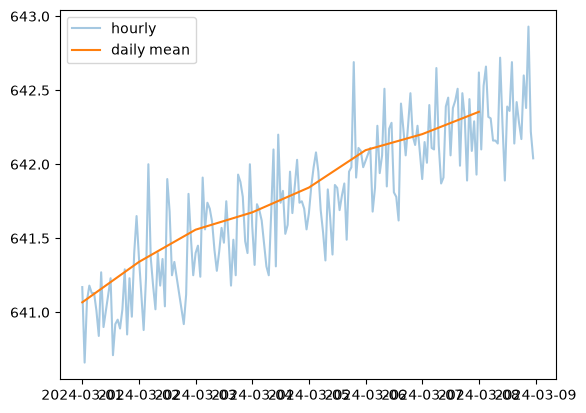

In [ ]:
import matplotlib.pyplot as plt
daily=df2['temp_out'].resample('D').mean()

plt.plot(df2.index, df2['temp_out'], alpha=0.4, label='hourly')
plt.plot(daily.index, daily.values, label='daily mean')
plt.legend()

plt.show()

In [ ]:
# 리스트의 데이터프레임화
name=['철수','짱구','맹구','훈이','유리']
score=[85,77,86,70,75]

dataf=pd.DataFrame({'이름':name, '점수':score})

dataf

,이름,점수
0,철수,85
1,짱구,77
2,맹구,86
3,훈이,70
4,유리,75


In [ ]:
# 20_02. 실습 8

In [199]:
df2.index

DatetimeIndex(['2024-03-01 00:00:00', '2024-03-01 01:00:00',
               '2024-03-01 02:00:00', '2024-03-01 03:00:00',
               '2024-03-01 04:00:00', '2024-03-01 05:00:00',
               '2024-03-01 06:00:00', '2024-03-01 07:00:00',
               '2024-03-01 08:00:00', '2024-03-01 09:00:00',
               ...
               '2024-03-08 14:00:00', '2024-03-08 15:00:00',
               '2024-03-08 16:00:00', '2024-03-08 17:00:00',
               '2024-03-08 18:00:00', '2024-03-08 19:00:00',
               '2024-03-08 20:00:00', '2024-03-08 21:00:00',
               '2024-03-08 22:00:00', '2024-03-08 23:00:00'],
              dtype='datetime64[us]', name='timestamp', length=182, freq=None)

In [203]:
df2['temp_core'].resample('30min').mean()

timestamp
2024-03-01 00:00:00    1399.16
2024-03-01 00:30:00        NaN
2024-03-01 01:00:00    1399.28
2024-03-01 01:30:00        NaN
2024-03-01 02:00:00    1394.97
                        ...   
2024-03-08 21:00:00    1415.71
2024-03-08 21:30:00        NaN
2024-03-08 22:00:00    1412.78
2024-03-08 22:30:00        NaN
2024-03-08 23:00:00    1419.19
Freq: 30min, Name: temp_core, Length: 383, dtype: float64

In [204]:
up1=df2['temp_core'].resample('30min').mean()

In [ ]:
# 30분 단위로 묶었을 때, 발생하는 결측치 : 30분 단위일 때는 결측치 존재
up1.isna().sum()

np.int64(201)

In [206]:
up1_filled=up1.interpolate()

In [ ]:
# 선형 보간 후, 결측치 확인 
up1_filled.isna().sum() # 결측치 0 -> 선형 보간 성공적

np.int64(0)

In [208]:
df2['vibration'].interpolate()
df2['flow'].interpolate()

timestamp
2024-03-01 00:00:00    8.34
2024-03-01 01:00:00    8.38
2024-03-01 02:00:00    8.44
2024-03-01 03:00:00    8.43
2024-03-01 04:00:00    8.42
                       ... 
2024-03-08 19:00:00    8.71
2024-03-08 20:00:00    8.66
2024-03-08 21:00:00    8.62
2024-03-08 22:00:00    8.68
2024-03-08 23:00:00    8.64
Name: flow, Length: 182, dtype: float64